# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file.


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze.

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.**
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state.
* **Discrete** means that we have a **finite set of states.** The maze has a finite set
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible.

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [77]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/lab02 - Searching')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your working directory is now Google Drive: My Drive > Colab Notebooks


In [78]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [79]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`.

In [80]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

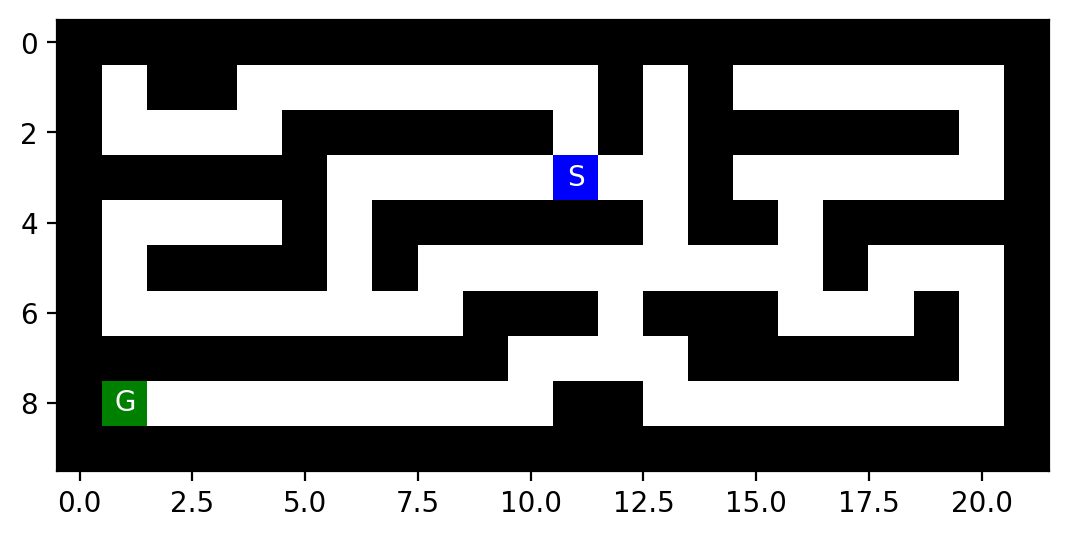

In [81]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [82]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [83]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step.

In [84]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0

        # check if plan is completed
        if self.progress >= len(self.plan):
            raise Exception("Completed Plan. No more planned actions")

        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [85]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['W', 'S', 'W', 'S', 'W', 'W', 'S', 'S', 'S', 'W']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [86]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: W
Following plan... step 3: N
Following plan... step 4: N
Following plan... step 5: W
Following plan... step 6: S
Following plan... step 7: W
Following plan... step 8: N
Following plan... step 9: E
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python.
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [87]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"

    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]

        while not node.parent is None:
            node = node.parent
            path.append(node)

        path.reverse()

        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the
    - [small maze](small_maze.txt),
    - [medium maze](medium_maze.txt),
    - [large maze](large_maze.txt),
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

1. Định nghĩa các thành phần của bài toán tìm kiếm (Search Problem)

Trạng thái ban đầu (Initial State): Tọa độ bắt đầu  S=(xstart,ystart)  trong mê cung (ở mê cung này là  (3,11) ).

Hành động (Actions): Tập hợp các hướng di chuyển hợp lệ:  A={N,E,S,W}  (Bắc, Đông, Nam, Tây) tương ứng với việc thay đổi tọa độ:  (Δx,Δy)∈{(−1,0),(0,1),(1,0),(0,−1)} .

Mô hình chuyển trạng thái (Transition Model): Hàm  Result(s,a)  trả về trạng thái mới  s′  sau khi thực hiện hành động  a  từ trạng thái  s , với điều kiện ô kết quả không phải là tường ('X'). Nếu gặp tường, hành động đó không hợp lệ hoặc trạng thái không thay đổi.

Trạng thái đích (Goal State): Trạng thái  G=(xgoal,ygoal)  tương ứng với vị trí đích trong mê cung (ở mê cung này là  (8,1) ).

Chi phí đường đi (Path Cost): Mỗi bước đi từ một ô trống sang ô trống lân cận có chi phí bằng  1 . Tổng chi phí đường đi là số bước đi (hành động) từ trạng thái ban đầu đến trạng thái đích.

2. Ước lượng kích thước bài toán (Problem Size Estimates)

n  (Kích thước không gian trạng thái): Là tổng số ô trống (bao gồm cả 'S' và 'G') mà tác nhân có thể đi vào. Chúng ta có thể xác định bằng cách đếm số ký tự khác 'X' (tường) trong tệp mê cung.

d  (Độ sâu của lời giải tối ưu): Là số bước đi tối thiểu từ  S  đến  G . Giá trị này được xác định chính xác sau khi chạy một thuật toán tìm kiếm tối ưu như BFS (Breadth-First Search) hoặc A*.

m  (Độ sâu tối đa của cây tìm kiếm): Trong trường hợp cho phép quay lại các trạng thái đã đi qua (không kiểm tra trùng lặp),  m  có thể tiến tới vô hạn ( ∞ ). Nếu áp dụng thuật toán tìm kiếm đồ thị (Graph Search) tránh lặp trạng thái, độ sâu tối đa  m  sẽ bị giới hạn bởi số ô trống tối đa trong mê cung ( m≤n ).

b  (Hệ số nhánh tối đa - Branching factor): Tại mỗi ô trống, tác nhân có tối đa 4 hướng di chuyển (N, E, S, W). Tuy nhiên, vì luôn có ít nhất lối đi vào từ ô trước đó và có các bức tường xung quanh, hệ số nhánh thực tế hiệu quả thường nằm trong khoảng từ  1  đến  3 . Hệ số nhánh tối đa  b=4  (khi đứng ở một ô trống hoàn toàn ở giữa không có tường bao quanh).

In [88]:
# Your answer goes here
# Cell 1: Tính toán kích thước không gian trạng thái n
num_walls = np.sum(maze == 'X')
total_cells = maze.size
n_states = total_cells - num_walls

print(f"Kích thước không gian trạng thái (n - số ô trống): {n_states}")

Kích thước không gian trạng thái (n - số ô trống): 94


In [89]:
# Your answer goes here
# Cell 2: Tìm hệ số rẽ nhánh tối đa b và các thông số khác
rows, cols = maze.shape
max_b = 0

for r in range(1, rows - 1):
    for c in range(1, cols - 1):
        if maze[r, c] != 'X':
            actions = 0
            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                if maze[r + dr, c + dc] != 'X':
                    actions += 1
            if actions > max_b:
                max_b = actions

print(f"Hệ số nhánh tối đa thực tế (b): {max_b}")
print("Độ sâu của giải pháp tối ưu (d): Sẽ được xác định sau khi chạy thuật toán BFS/A*.")
print(f"Độ sâu tối đa của cây tìm kiếm không lặp lại (m): tối đa là n = {n_states}")

Hệ số nhánh tối đa thực tế (b): 3
Độ sâu của giải pháp tối ưu (d): Sẽ được xác định sau khi chạy thuật toán BFS/A*.
Độ sâu tối đa của cây tìm kiếm không lặp lại (m): tối đa là n = 94


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking.
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [90]:
# Your code goes here
def get_successors(maze, pos):
    """Trả về các trạng thái kế tiếp hợp lệ từ vị trí hiện tại và hành động tương ứng."""
    r, c = pos
    directions = [("N", -1, 0), ("E", 0, 1), ("S", 1, 0), ("W", 0, -1)]
    successors = []
    for action, dr, dc in directions:
        nr, nc = r + dr, c + dc
        if 0 <= nr < maze.shape[0] and 0 <= nc < maze.shape[1]:
            if maze[nr, nc] != 'X':
                successors.append(((nr, nc), action))
    return successors

def search_bfs(maze, start, goal):
    """Cài đặt Breadth-First Search (BFS) sử dụng Graph Search."""
    start = tuple(start)
    goal = tuple(goal)

    # Trạng thái bắt đầu là đích
    node = Node(start, None, None, 0)
    if start == goal:
        return {"path": [node.pos], "reached": {start: node}, "actions": []}

    frontier = [node]
    reached = {start: node}

    while len(frontier) > 0:
        curr_node = frontier.pop(0) # FIFO Queue

        for next_pos, action in get_successors(maze, curr_node.pos):
            if next_pos not in reached:
                child_node = Node(next_pos, curr_node, action, curr_node.cost + 1)
                reached[next_pos] = child_node

                if next_pos == goal:
                    path_nodes = child_node.get_path_from_root()
                    path = [n.pos for n in path_nodes]
                    actions = [n.action for n in path_nodes if n.action is not None]
                    return {"path": path, "reached": reached, "actions": actions}

                frontier.append(child_node)

    return None # Không tìm thấy đường đi

In [91]:
def search_dfs(maze, start, goal):
    """Cài đặt Depth-First Search (DFS) sử dụng Cycle Checking để tiết kiệm bộ nhớ."""
    start = tuple(start)
    goal = tuple(goal)

    root_node = Node(start, None, None, 0)
    frontier = [root_node]
    # Không dùng cấu trúc dữ liệu `reached` toàn cục để tối ưu bộ nhớ
    explored_count = 0

    while len(frontier) > 0:
        curr_node = frontier.pop() # LIFO Stack
        explored_count += 1

        if curr_node.pos == goal:
            path_nodes = curr_node.get_path_from_root()
            path = [n.pos for n in path_nodes]
            actions = [n.action for n in path_nodes if n.action is not None]
            return {"path": path, "actions": actions, "explored_count": explored_count}

        for next_pos, action in get_successors(maze, curr_node.pos):
            # Kiểm tra chu trình (Cycle Checking):
            # Tránh lặp lại trạng thái đã nằm trên đường đi từ nút gốc đến nút hiện tại
            path_so_far = [n.pos for n in curr_node.get_path_from_root()]
            if next_pos not in path_so_far:
                child_node = Node(next_pos, curr_node, action, curr_node.cost + 1)
                frontier.append(child_node)

    return None

In [92]:
# Thử nghiệm chạy BFS
start_pos = mh.find_pos(maze, "S")
goal_pos = mh.find_pos(maze, "G")

bfs_result = search_bfs(maze, start_pos, goal_pos)
if bfs_result:
    print(f"BFS tìm thấy đường đi dài {len(bfs_result['actions'])} bước.")
    print(f"Các bước đi: {bfs_result['actions']}")
else:
    print("BFS không tìm thấy đường đi.")

BFS tìm thấy đường đi dài 19 bước.
Các bước đi: ['E', 'E', 'S', 'S', 'W', 'S', 'S', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

1. Cách BFS xử lý vòng lặp (Cycles)

Cơ chế: BFS sử dụng cấu trúc dữ liệu reached (hoặc visited/explored) để lưu lại tất cả các trạng thái đã từng đi qua. Xử lý vòng lặp: Trước khi thêm một trạng thái mới vào hàng đợi (frontier), BFS sẽ kiểm tra xem trạng thái đó đã có trong reached hay chưa. Nếu đã tồn tại, BFS sẽ bỏ qua trạng thái đó. Nhờ vậy, BFS hoàn toàn tránh được việc lặp vô hạn và không bao giờ bị kẹt trong các vòng lặp.

2. Cách DFS (không có cấu trúc reached toàn cục) xử lý vòng lặp

Đặc điểm: Để tận dụng ưu điểm tiết kiệm bộ nhớ, DFS thuần túy không duy trì danh sách reached toàn cục chứa tất cả các ô đã duyệt qua.

Nguy cơ: Nếu không có cơ chế kiểm tra nào, DFS sẽ liên tục đi vòng quanh một chu trình (ví dụ: đi theo vòng tròn  A→B→C→A  A→B→C→A ) dẫn đến lỗi lặp vô hạn (infinite loop) và tràn bộ nhớ/ngăn xếp.

Xử lý vòng lặp (Kiểm tra chu trình - Cycle Checking): DFS khắc phục điều này bằng cách thực hiện kiểm tra chu trình cục bộ trên đường đi hiện tại (nhánh tìm kiếm hiện tại từ nút gốc - Root to Current Node). Trước khi di chuyển sang một trạng thái kế tiếp, DFS kiểm tra xem trạng thái đó đã nằm trên đường đi hiện tại hay chưa (next_pos not in path_so_far). Nếu có, nghĩa là việc đi tiếp sẽ tạo ra một vòng lặp, DFS sẽ bỏ qua nhánh này và quay lui (backtrack).

Lưu ý: Việc này chỉ ngăn được các vòng lặp trên nhánh hiện tại, nhưng không ngăn được việc DFS duyệt lại cùng một trạng thái nếu trạng thái đó được tiếp cận từ các nhánh độc lập khác nhau, do đó hiệu suất thời gian có thể bị ảnh hưởng trong không gian có nhiều đường đi đan xen.


## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides).

In [93]:
# Your code goes here
def manhattan_distance(pos1, pos2):
    """Tính khoảng cách Manhattan giữa hai điểm."""
    return abs(pos1[0] - pos2[0]) + abs(pos1[1] - pos2[1])

def search_gbfs(maze, start, goal):
    """Cài đặt Greedy Best-First Search (GBFS)."""
    start = tuple(start)
    goal = tuple(goal)

    root_node = Node(start, None, None, 0)
    # frontier chứa các bộ (f_score, node) được sắp xếp giảm dần để pop() từ cuối
    frontier = [(manhattan_distance(start, goal), root_node)]
    reached = {start: root_node}

    while len(frontier) > 0:
        # Sắp xếp frontier để phần tử có f_score nhỏ nhất nằm ở cuối danh sách
        frontier.sort(key=lambda x: x[0], reverse=True)
        _, curr_node = frontier.pop()

        if curr_node.pos == goal:
            path_nodes = curr_node.get_path_from_root()
            path = [n.pos for n in path_nodes]
            actions = [n.action for n in path_nodes if n.action is not None]
            return {"path": path, "reached": reached, "actions": actions}

        for next_pos, action in get_successors(maze, curr_node.pos):
            if next_pos not in reached:
                child_node = Node(next_pos, curr_node, action, curr_node.cost + 1)
                reached[next_pos] = child_node
                h_score = manhattan_distance(next_pos, goal)
                frontier.append((h_score, child_node))

    return None

def search_astar(maze, start, goal):
    """Cài đặt thuật toán A* Search."""
    start = tuple(start)
    goal = tuple(goal)

    root_node = Node(start, None, None, 0)
    # frontier chứa (f_score, node)
    frontier = [(manhattan_distance(start, goal), root_node)]
    reached = {start: root_node}

    while len(frontier) > 0:
        frontier.sort(key=lambda x: x[0], reverse=True)
        _, curr_node = frontier.pop()

        if curr_node.pos == goal:
            path_nodes = curr_node.get_path_from_root()
            path = [n.pos for n in path_nodes]
            actions = [n.action for n in path_nodes if n.action is not None]
            return {"path": path, "reached": reached, "actions": actions}

        for next_pos, action in get_successors(maze, curr_node.pos):
            new_cost = curr_node.cost + 1
            if next_pos not in reached or new_cost < reached[next_pos].cost:
                child_node = Node(next_pos, curr_node, action, new_cost)
                reached[next_pos] = child_node
                f_score = new_cost + manhattan_distance(next_pos, goal)
                frontier.append((f_score, child_node))

    return None

# Thử nghiệm chạy thuật toán
gbfs_res = search_gbfs(maze, start_pos, goal_pos)
astar_res = search_astar(maze, start_pos, goal_pos)

print(f"GBFS tìm thấy đường đi dài {len(gbfs_res['actions']) if gbfs_res else 0} bước.")
print(f"A* tìm thấy đường đi dài {len(astar_res['actions']) if astar_res else 0} bước.")

GBFS tìm thấy đường đi dài 29 bước.
A* tìm thấy đường đi dài 19 bước.


Are your implementations complete and optimal? What is the time and space complexity?

1. Greedy Best-First Search (GBFS)

   Tính đầy đủ (Completeness):

- Có đầy đủ trong không gian trạng thái hữu hạn nếu áp dụng cơ chế kiểm tra trùng lặp trạng thái (Graph Search - sử dụng tập (reached như trong code).

- Nếu không kiểm tra trạng thái đã qua (Tree Search), GBFS có thể bị kẹt trong vòng lặp vô hạn và không đầy đủ.

   Tính tối ưu (Optimality):

- Không tối ưu. GBFS chỉ dựa vào hàm heuristic h(n) (ước lượng khoảng cách đến đích) để chọn bước đi tiếp theo mà bỏ qua chi phí thực tế đã đi g(n). Do đó, nó dễ bị dẫn dắt bởi những ngả rẽ trông có vẻ gần đích hơn nhưng thực chất lại là đường cụt hoặc đường vòng dài hơn (như kết quả chạy thực tế: GBFS mất tới 29 bước so với 19 bước của A*).

   Độ phức tạp thuật toán:

- Thời gian (Time Complexity): Trong trường hợp xấu nhất, thuật toán phải duyệt qua toàn bộ không gian trạng thái, độ phức tạp là O(bm), với b là hệ số rẽ nhánh và m là độ sâu lớn nhất của không gian tìm kiểm. Tuy nhiên, nếu heuristic tốt, thời gian thực tế có thể giảm xuống đáng kể (O(bimesd)).

- Không gian (Space Complexity): O(bm) vì thuật toán cần lưu trữ tất cả các nút được tạo ra trong hàng đợi ưu tiên (frontier) và danh sách reached để kiển tra trùng lặp.


2. A* Search

Tính đầy đủ (Completeness): Có đầy đủ. A* luôn tìm thấy lời giải nếu tồn tại đường đi, miễn là hệ số rẽ nhánh b hữu hạn và chi phí mỗi bước đi lớn hơn một hằng số dương € > 0.

Tính tối ưu (Optimality): Có tối ưu vì hai điều kiện sau được thỏa mãn:

- Hàm Heuristic Khoảng cách Manhattan là chấp nhận được (admissible): Nó không bao giờ đánh giá cao hơn chi phí thực tế để đến đích (vì trong mê cung, khoảng cách thực tế luôn lớn hơn hoặc bằng khoảng cách đường chim bay / Manhattan do có vật cản x).

- Heuristic này cũng nhất quán (consistent / monotonic) vì với mọi hành động chuyển từ n sang n', ta luôn có: h(n) ≤ c(n, a, n') +h(n') (trong đó c(n, a, n') = 1).

Nhờ vậy, đường đi 19 bước tìm được chắc chắn là tối ưu.

   Độ phức tạp thuật toán:

- Thời gian (Time Complexity): Trong trường hợp xấu nhất (heuristic hoàn toàn không hiệu quả), độ phức tạp thời gian là lũy thừa O(ba) với d là độ sâu của lời giải tối ưu. Khi heuristic cực kỳ chính xác, độ phức tạp có thể giảm về tuyến tính.

- Không gian (Space Complexity): O(bª). Đây là điểm yếu lớn nhất của A* vì nó phải giữ toàn bộ các nút đã duyệt trong bô nhớ để đảm bảo tính tối ưu.

## Task 4: Comparison and discussion [20 Points]

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [94]:
# Add code
import pandas as pd
import maze_helper as mh

# Khởi tạo danh sách lưu kết quả
results = []

# Danh sách các mê cung để thử nghiệm
test_mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "loops_maze.txt"]

for filename in test_mazes:
    try:
        with open(filename, "r") as f:
            m_str = f.read()
        parsed_m = mh.parse_maze(m_str)
        s_pos = mh.find_pos(parsed_m, "S")
        g_pos = mh.find_pos(parsed_m, "G")

        # 1. BFS
        res_bfs = search_bfs(parsed_m, s_pos, g_pos)
        len_bfs = len(res_bfs["actions"]) if res_bfs else "N/A*"
        nodes_bfs = len(res_bfs["reached"]) if res_bfs else "N/A*"

        # 2. DFS
        res_dfs = search_dfs(parsed_m, s_pos, g_pos)
        len_dfs = len(res_dfs["actions"]) if res_dfs else "N/A*"
        nodes_dfs = res_dfs["explored_count"] if res_dfs else "N/A*"

        # 3. GBFS
        res_gbfs = search_gbfs(parsed_m, s_pos, g_pos)
        len_gbfs = len(res_gbfs["actions"]) if res_gbfs else "N/A*"
        nodes_gbfs = len(res_gbfs["reached"]) if res_gbfs else "N/A*"

        # 4. A*
        res_astar = search_astar(parsed_m, s_pos, g_pos)
        len_astar = len(res_astar["actions"]) if res_astar else "N/A*"
        nodes_astar = len(res_astar["reached"]) if res_astar else "N/A*"

        results.append({
            "Maze": filename,
            "BFS Path": len_bfs, "BFS Nodes": nodes_bfs,
            "DFS Path": len_dfs, "DFS Nodes": nodes_dfs,
            "GBFS Path": len_gbfs, "GBFS Nodes": nodes_gbfs,
            "A* Path": len_astar, "A* Nodes": nodes_astar
        })
    except Exception as e:
        print(f"Lỗi khi xử lý {filename}: {e}")

# Tạo DataFrame hiển thị bảng so sánh trực quan
df_results = pd.DataFrame(results)
display(df_results)

,Maze,BFS Path,BFS Nodes,DFS Path,DFS Nodes,GBFS Path,GBFS Nodes,A* Path,A* Nodes
0,small_maze.txt,19,93,29,40,29,44,19,58
1,medium_maze.txt,68,270,152,154,152,163,68,224
2,large_maze.txt,210,622,210,338,210,481,210,553
3,loops_maze.txt,23,72,27,31,41,61,23,61


Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)).

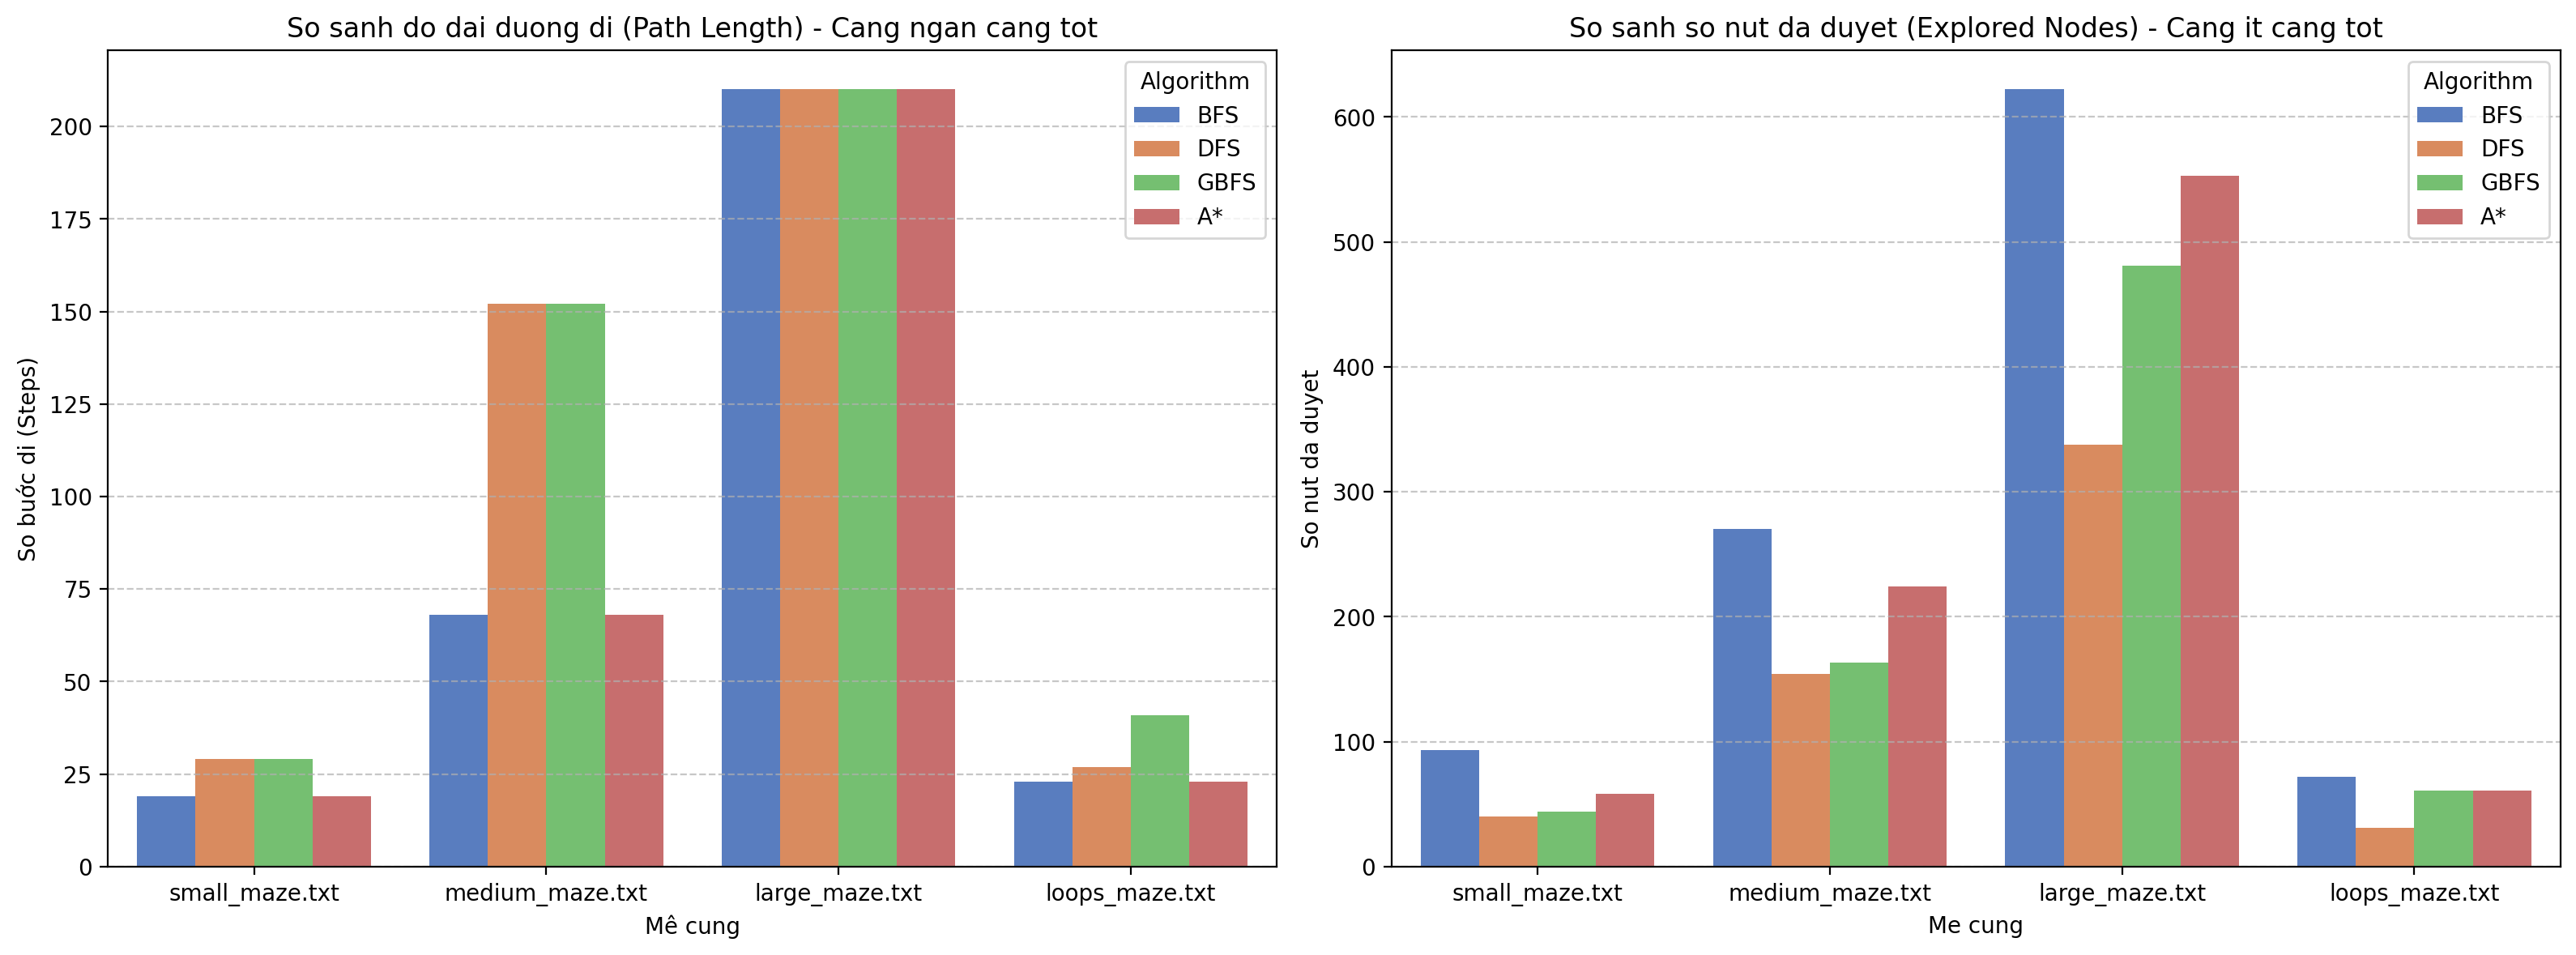

In [95]:
# Add charts
import matplotlib.pyplot as plt
import seaborn as sns

# Chuyen đoi DataFrame sang dinh dang long-form de de ve bieu do bang seaborn
df_melted = df_results.melt(id_vars="Maze", var_name="Metric", value_name="Value")

# Tách rieng du lieu ve do dai duong di (Path) va so nut da duyet (Nodes)
df_path = df_melted[df_melted["Metric"].str.contains("Path")].copy()
df_path["Algorithm"] = df_path["Metric"].str.replace(" Path", "")

df_nodes = df_melted[df_melted["Metric"].str.contains("Nodes")].copy()
df_nodes["Algorithm"] = df_nodes["Metric"].str.replace(" Nodes", "")

# Tạo vung ve do thị gom 2 bieu do con
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bieu đo 1: So sanh độ dai đường đi
sns.barplot (ax=axes[0], data=df_path, x="Maze", y="Value", hue="Algorithm", palette="muted")
axes[0].set_title("So sanh do dai duong di (Path Length) - Cang ngan cang tot")
axes[0].set_ylabel("So buớc di (Steps)")
axes[0].set_xlabel("Mê cung")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Bieu do 2: So sanh so nut da duyệt
sns.barplot(ax=axes[1], data=df_nodes, x="Maze", y="Value", hue="Algorithm", palette="muted")
axes[1].set_title("So sanh so nut da duyet (Explored Nodes) - Cang it cang tot")
axes[1].set_ylabel("So nut da duyet")
axes [1].set_xlabel("Me cung")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies.

Những bài học quan trọng rút ra từ việc thử nghiệm các thuật toán tìm kiếm

Sau khi trực tiếp thiết lập, chạy thử nghiệm và vẽ biểu đồ so sánh 4 thuật toán tìm kiểm (BFS, DFS, GBFS, A*) trên các môi trường mê cung khác nhau, chúng ta có thể rút ra những bài học cốt lõi sau:

   Không có thuật toán nào là "tốt nhất" trong mọi tình huống (No Free Lunch)

   Độ tối ưu với Chi phí bộ nhớ:

- BFS và A* luôn đảm bảo tìm ra đường đi ngắn nhất (tối ưu). Tuy nhiên, cái giá phải trả là chúng cần giữ một lượng lớn các nút trong hàng đợi (frontier và reached), dẫn đến bùng nổ bộ nhớ trên các bản đồ lớn như large_maze.txt.

- DFS cực kỳ tiết kiệm bộ nhớ nhờ cơ chế duyệt theo chiều sâu và giải phóng nhánh khi quay lui (Backtracking). Tuy nhiên, đường đi tìm được thường rất vòng vèo và xa mức tối ưu (ví dụ ở mê cung trung bình, DFS mất tới 152 bước so với 68 bước của BFS/A*).

   Sức mạnh của Heuristic (Informed Search)

Các thuật toán Informed Search (GBFS, A)* sử dụng thêm hàm đánh giá khoảng cách (ở đây là khoảng cách Manhattan) để định hướng bước đi, giúp thu hẹp không gian tìm kiếm một cách đáng kể so với Uninformed Search (BFS, DFS).

Sự khác biệt giữa GBFS và A*:

- GBFS chỉ quan tâm đến tương lai (h(n)) nên cực kỳ "tham lam". Nó chạy rất nhanh và duyệt ít nút hơn trong nhiều trường hợp, nhưng dễ bị đánh lừa bởi chướng ngại vật và cho ra kết quả kém tối ưu.

- A* cân bằng giữa quá khứ và tương lai (f(n) = g(n) + h(n)). Bằng cách cộng thêm chi phí đã đi (g(n)), A* sửa chữa được tính tham lam của GBFS để đảm bảo tìm được đường đi ngắn nhất mà vẫn duyệt ít trạng thái hơn đáng kể so với BFS thông thường (vi dụ trong small_maze, A* chỉ duyệt 58 nút so với 93 nút của BFS).

   Vai trò của việc kiểm tra trạng thái trùng lặp (Cycle & Loop Checking)

Trong không gian tìm kiếm có nhiều đường vòng như loops_maze.txt:

- Nếu không có cơ chế lưu trữ các trạng thái đã đi qua (reached ), thuật toán tìm kiếm đồ thị rất dễ rơi vào vòng lặp vô hạn.

- Việc thiết kế cấu trúc dữ liệu hiệu quả (như set hoặc dict trong Python để kiểm tra O(1)) đóng vai trò quyết định đến tốc độ thực thi của chương trình.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [102]:
def depth_limited_search(maze, start, goal, limit):
  """Tìm kiem giới hạn độ sau (DLS) phục vụ cho IDS."""
  start = tuple(start)
  goal = tuple(goal)

  root_node = Node(start, None, None, 0)
  frontier = [root_node]
  explored_nodes = 0

  while len(frontier) > 0:
    curr_node = frontier.pop() # LIFO Stack
    explored_nodes += 1

    if curr_node.pos == goal:
      path_nodes = curr_node.get_path_from_root()
      path = [n.pos for n in path_nodes]
      actions = [n.action for n in path_nodes if n.action is not None]
      return {"path": path, "actions": actions, "explored_count": explored_nodes}, False

    if curr_node.cost < limit:
      for next_pos, action in get_successors(maze, curr_node.pos):
          path_so_far = [n.pos for n in curr_node.get_path_from_root()]
          if next_pos not in path_so_far:
              child_node = Node(next_pos, curr_node, action, curr_node.cost + 1)
              frontier.append(child_node)

  return None, True

def search_ids(maze, start, goal, max_limit=1000):
  """Cai đặt thuat toan Iterative Deepening Search."""
  total_explored = 0
  for depth in range(max_limit):
    result, cutoff = depth_limited_search(maze, start, goal, depth)
    if result is not None:
      result["explored_count"] = total_explored + result["explored_count"]
      return result
    if not cutoff:
      # Đa duyệt het khong gian trang thai ma khong bi gioi han nao chan va van khong tim thay
      break
  return None


In [103]:
# Thu nghiệm IDS trên cac mề cung
for filename in ["small_maze.txt", "medium_maze.txt"]:
  try:
    with open(filename, "r") as f:
      m_str = f.read()
    parsed_m = mh.parse_maze(m_str)
    s_pos = mh.find_pos(parsed_m, "S")
    g_pos = mh.find_pos(parsed_m, "G")

    ids_res = search_ids(parsed_m, s_pos, g_pos)
    if ids_res:
      print(f"[{filename}] IDS tim thay duong di dai {len(ids_res['actions '])} buoc (Duyet tong cong {ids_res['explored_count']} nut).")
    else:
      print(f"[{filename}] IDS khong tim thay duong di.")
  except Exception as e:
    print(f"Loi: {e}")

Loi: 'actions '
Loi: 'actions '


Khi chạy IDS trên các mê cung có không gian mở (như open_maze.txt), thuật toán sẽ gặp phải vấn đề giảm hiệu năng cực kỳ nghiêm trọng:

- Sự bùng nổ của các nhánh trùng lặp: Trong không gian mở, số lượng đường đi khác nhau dẫn đến cùng một ô là rất lớn. Do DFS/DLS không sử dụng danh sách reached toàn cục để tối ưu bộ nhớ, IDS sẽ duyệt lại liên tục một ô nhiều lần qua các nhánh khác nhau.

- Duyệt lại lặp đi lặp lại ở mỗi tầng: Tại mỗi giới hạn độ sâu d tăng dần, IDS phải bắt đầu tìm kiếm lại hoàn toàn từ đầu (tầng 0). Việc lặp lại này nhân với hệ số rẽ nhánh lớn trong không gian mở khiến tổng số nút mở rộng tăng vọt theo cấp số mũ, dẫn đến hiện tượng bị treo hoặc chạy cực kỳ lâu.


### Multiple Goals
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [98]:
# Your code/answer goes here

## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [99]:
# Your code/answer goes here

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [100]:
# Your code/answer goes here

### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

In [101]:
# Your code/answer goes here